[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/02-data-science/12_time-series.ipynb)

*Python for Data Science · Notebook 12 of 12*

# Time Series & Forecasting

Work with data ordered in time: resampling and missing dates, lags, rolling and exponential averages, trend and seasonality, autocorrelation, baseline and smoothing forecasts, autoregression, honest time-based validation, forecast errors and anomaly flags.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A time series is a diary: order matters, yesterday explains today, and you can never read tomorrow's page while writing today's.

**What interviewers really test here:** Trend vs seasonality, why you can't shuffle, baselines, walk-forward validation, leakage in lag features, and MAE vs MAPE.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What makes time series different *(Basics)*
- [ ] 2. Lags, changes and smoothing *(Basics)*
- [ ] 3. Trend, seasonality and autocorrelation *(Core)*
- [ ] 4. Forecasting: start with baselines *(Core)*
- [ ] 5. Models: smoothing, trend lines and autoregression *(Advanced)*
- [ ] 6. Validating forecasts honestly, and spotting anomalies *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Components

| Part | Meaning | Example |
| --- | --- | --- |
| Trend | long-run rise or fall | growing user base |
| Seasonality | fixed-length repeating pattern | weekend peaks, Diwali sales |
| Cycle | rises and falls without a fixed length | economic cycles |
| Noise | what's left | random day-to-day variation |



**Additive**: y = trend + season + noise (seasonal swings stay the same size). **Multiplicative**: y = trend × season × noise (swings grow with the level); taking logs turns it additive.

### Stationarity

A series is **stationary** if its mean, variance and autocorrelation don't change over time. Many classical models (ARIMA) assume it. Make a series more stationary by **differencing** (removes trend), **seasonal differencing** (x~t − x~t−m) and **log transforms** (stabilises growing variance). The Augmented Dickey–Fuller test checks it formally.

### Error metrics

| Metric | Formula | Note |
| --- | --- | --- |
| MAE | mean \|y − ŷ\| | same units as data, robust |
| RMSE | √mean (y − ŷ)² | punishes large errors |
| MAPE | mean \|y − ŷ\| / \|y\| | undefined at y = 0, favours under-forecasts |
| MASE | MAE / MAE of the naive forecast | &lt; 1 beats naive; comparable across series |

---
# Part 2: Lessons, step by step

## Lesson 1: What makes time series different

*Level: Basics*

In most data the row order doesn't matter. In a **time series** — daily sales, hourly server load, monthly sign-ups — order is everything, and today's value depends on yesterday's. That changes three rules:




- The index is a date: parse it (`pd.to_datetime`), sort by it, and make the frequency explicit.
- Missing dates are information: a day with no sales row usually means 0 sales, not "unknown".
- **Never shuffle.** Train on the past, test on the future, or your model peeks at answers.



```python
s = pd.Series(values, index=pd.to_datetime(days))
s.resample("W").sum()          # daily → weekly ("MS" monthly, "h" hourly)
s.asfreq("D", fill_value=0)    # put back the missing days
```

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 2: Lags, changes and smoothing

*Level: Basics*

```python
s.shift(1)            # yesterday's value on today's row
s.diff()              # change since yesterday
s.pct_change(12)      # % change vs 12 periods ago (year over year for monthly data)
s.rolling(7).mean()   # 7-day moving average: hides day-to-day noise
s.ewm(alpha=0.3, adjust=False).mean()   # recent days count more
```



A rolling average weights the last k values equally and drops older ones completely. An **exponential** moving average gives every past value some weight, shrinking by (1 − α) each step: a big α reacts fast, a small α is smooth. Comparing with the same period last year (YoY) removes seasonality from growth numbers.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

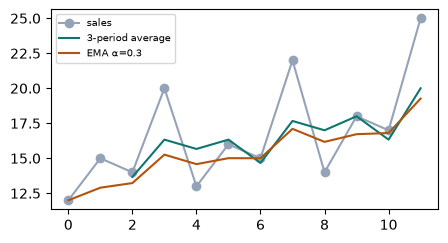

In [2]:
def smoothing_picture():
    s = pd.Series([12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], dtype=float)
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.plot(s, marker="o", color="#94a3b8", label="sales")
    ax.plot(s.rolling(3).mean(), color="#0f766e", label="3-period average")
    ax.plot(s.ewm(alpha=0.3, adjust=False).mean(), color="#b45309", label="EMA α=0.3")
    ax.legend(fontsize=7)


smoothing_picture()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q11](#q11), [Q8](#q8), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 3: Trend, seasonality and autocorrelation

*Level: Core*

Most series are a mix of three parts: **trend** (the long-run direction), **seasonality** (a pattern that repeats every m periods: weekdays, months, festivals) and **noise**. Classical decomposition estimates the trend with a centred moving average of length m, then averages what's left at each position in the cycle to get the seasonal indices.



**Autocorrelation** at lag k is the correlation between the series and itself k steps earlier. A peak at lag 7 in daily data means a weekly pattern; at lag 12 in monthly data, a yearly one. It's the quickest way to find the season length.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

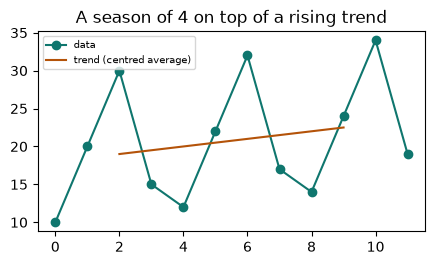

In [3]:
SEASONAL = [10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19]


def seasonal_picture():
    s = pd.Series(SEASONAL, dtype=float)
    trend = s.rolling(4).mean().rolling(2).mean().shift(-2)
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.plot(s, marker="o", color="#0f766e", label="data")
    ax.plot(trend, color="#b45309", label="trend (centred average)")
    ax.legend(fontsize=7)
    ax.set_title("A season of 4 on top of a rising trend")


seasonal_picture()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 4: Forecasting: start with baselines

*Level: Core*

Before any model, compute three **baselines**:




- **Naive**: tomorrow = today. Hard to beat for stock prices and other random walks.
- **Mean**: the historical average. Good for stable, patternless series.
- **Seasonal naive**: next Monday = last Monday. Strong whenever there's seasonality.



A fancy model is only worth it if it beats the best baseline on held-out data. Measure with **MAE** (average miss, in the data's units), **RMSE** (punishes big misses) or **MAPE** (percent, but breaks near zero).

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 5: Models: smoothing, trend lines and autoregression

*Level: Advanced*

- **Simple exponential smoothing** forecasts the latest smoothed level; choose α by the smallest one-step-ahead error. **Holt** adds a trend term and **Holt–Winters** a seasonal one (statsmodels' `ExponentialSmoothing`).
- **Linear trend**: regress the value on time. Fine for short horizons; dangerous to extrapolate far.
- **Autoregression AR(p)**: regress today on the last p values. ARIMA adds differencing (to remove trend) and moving-average error terms; SARIMA adds seasonality.
- **Machine learning**: turn the series into a table of lag features, rolling statistics and calendar features (weekday, month, holiday), then use gradient boosting. This is how most large-scale demand forecasting is done today; Prophet and deep models (N-BEATS, temporal transformers) are other options.

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q19](#q19), [Q20](#q20), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 6: Validating forecasts honestly, and spotting anomalies

*Level: Advanced*

**Walk-forward validation**: train on data up to a cut-off, forecast the next block, move the cut-off forward, repeat. Average the errors over the folds. It mimics how the model will really be used. Features must only use information available at forecast time — a 7-day rolling mean that includes today leaks today's answer.



**Anomaly detection** flags values far from what the recent past predicts: compare each point with the mean and standard deviation of the window *before* it. Note one big spike inflates the next windows' standard deviation and can hide a second anomaly; robust versions use the median and the median absolute deviation instead.

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [4]:
from datetime import date, timedelta

import math


<a id="q1"></a>
### Q1. Daily to Weekly Totals

🟢 Warm-up · *resample*

`days` are ISO dates with `values`. Return weekly totals keyed by the week's last day (Sunday), like pandas `resample('W')`.

**Examples**

- `days = ['2026-03-02', '2026-03-04', '2026-03-08', '2026-03-09', '2026-03-15'], values = [5, 3, 2, 7, 1]` → `{'2026-03-08': 10, '2026-03-15': 8}`

In [ ]:
def weekly(days, values):
    """
    days are ISO dates with values. Return weekly totals keyed by the week's
    last day (Sunday), like pandas resample('W').
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weekly, [
    ((['2026-03-02', '2026-03-04', '2026-03-08', '2026-03-09', '2026-03-15'], [5, 3, 2, 7, 1]), {'2026-03-08': 10, '2026-03-15': 8}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each date, jump forward to its Sunday and add into a dict.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A DatetimeIndex and `resample('W').sum()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** For each date, jump forward to its Sunday and add into a dict.

```python
def weekly(days, values):
    out = {}
    for d, v in zip(days, values):
        day = date.fromisoformat(d)
        sunday = day + timedelta(days=6 - day.weekday())
        out[str(sunday)] = out.get(str(sunday), 0) + v
    return dict(sorted(out.items()))
```

**Cost:** O(n) time, O(weeks) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** A DatetimeIndex and `resample('W').sum()`.

```python
def weekly(days, values):
    s = pd.Series(values, index=pd.to_datetime(days)).resample("W").sum()
    return {str(k.date()): int(v) for k, v in s.items()}
```

**Cost:** O(n) time, O(weeks) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each date, jump forward to its Sunday and add into a dict. That costs O(n) time and O(weeks) space."

"I can do better: A DatetimeIndex and `resample('W').sum()`. That's O(n) time and O(weeks) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/daily-to-weekly-totals)

<a id="q2"></a>
### Q2. Fill Missing Dates

🟢 Warm-up · *asfreq*

Sales data skips days with no sales. Return the full daily list of values from the first to the last date, with 0 on missing days.

**Examples**

- `days = ['2026-03-01', '2026-03-02', '2026-03-05'], values = [4, 6, 1]` → `[4, 6, 0, 0, 1]`

In [ ]:
def fill_days(days, values):
    """
    Sales data skips days with no sales. Return the full daily list of values
    from the first to the last date, with 0 on missing days.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fill_days, [
    ((['2026-03-01', '2026-03-02', '2026-03-05'], [4, 6, 1]), [4, 6, 0, 0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk day by day with `timedelta`, using a dict lookup.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`asfreq('D', fill_value=0)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Walk day by day with `timedelta`, using a dict lookup.

```python
def fill_days(days, values):
    known = dict(zip(days, values))
    d, end = date.fromisoformat(days[0]), date.fromisoformat(days[-1])
    out = []
    while d <= end:
        out.append(known.get(str(d), 0))
        d += timedelta(days=1)
    return out
```

**Cost:** O(days) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `asfreq('D', fill_value=0)`.

```python
def fill_days(days, values):
    return pd.Series(values, index=pd.to_datetime(days)).asfreq("D", fill_value=0).tolist()
```

**Cost:** O(days) time, O(days) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk day by day with `timedelta`, using a dict lookup. That costs O(days) time and O(n) space."

"I can do better: `asfreq('D', fill_value=0)`. That's O(days) time and O(days) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/fill-missing-dates)

<a id="q3"></a>
### Q3. Lags and Differences

🟢 Warm-up · *shift · diff*

Return `(lag-1 values, first differences)`, with None where there's no earlier value.

**Examples**

- `values = [12, 15, 14, 20, 13]` → `([None, 12.0, 15.0, 14.0, 20.0], [None, 3.0, -1.0, 6.0, -7.0])`

In [ ]:
def lags(values):
    """
    Return (lag-1 values, first differences), with None where there's no earlier
    value.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lags, [
    (([12, 15, 14, 20, 13],), ([None, 12.0, 15.0, 14.0, 20.0], [None, 3.0, -1.0, 6.0, -7.0])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Index arithmetic in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`s.shift(1)` and `s.diff()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Index arithmetic in a loop.

```python
def lags(values):
    lag = [None] + values[:-1]
    diff = [None] + [values[i] - values[i - 1] for i in range(1, len(values))]
    return (lag, diff)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `s.shift(1)` and `s.diff()`.

```python
def lags(values):
    s = pd.Series(values, dtype=float)
    return (s.shift(1).tolist(), s.diff().tolist())
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Index arithmetic in a loop. That costs O(n) time and O(n) space."

"I can do better: `s.shift(1)` and `s.diff()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/lags-and-differences)

<a id="q4"></a>
### Q4. Rolling Average

🟢 Warm-up · *Smoothing noise*

Return the `k`-period trailing moving average (None until there are k values), rounded to 2.

**Examples**

- `values = [12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], k = 3` → `[None, None, 13.67, 16.33, 15.67, 16.33, 14.67, 17.67, 17.0, 18.0, 16.33, 20.0]`
- `values = [12, 15, 14, 20], k = 4` → `[None, None, None, 15.25]`

In [ ]:
def rolling_mean(values, k):
    """
    Return the k-period trailing moving average (None until there are k values),
    rounded to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rolling_mean, [
    (([12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], 3), [None, None, 13.67, 16.33, 15.67, 16.33, 14.67, 17.67, 17.0, 18.0, 16.33, 20.0]),
    (([12, 15, 14, 20], 4), [None, None, None, 15.25]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Re-add each window, or slide a running sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`s.rolling(k).mean()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Re-add each window, or slide a running sum.

```python
def rolling_mean(values, k):
    out = []
    total = 0
    for i, v in enumerate(values):
        total += v
        if i >= k:
            total -= values[i - k]
        out.append(round(total / k, 2) if i >= k - 1 else None)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `s.rolling(k).mean()`.

```python
def rolling_mean(values, k):
    return pd.Series(values).rolling(k).mean().round(2).tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Re-add each window, or slide a running sum. That costs O(n) time and O(n) space."

"I can do better: `s.rolling(k).mean()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/rolling-average)

<a id="q5"></a>
### Q5. Baseline Forecasts

🟢 Warm-up · *Naive, mean, seasonal naive*

Forecast the next `h` values with three baselines. Return `(naive, mean, seasonal naive)` lists, where the season length is `m`. Means are rounded to 2.

**Examples**

- `values = [12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], h = 4, m = 4` → `([25, 25, 25, 25], [16.75, 16.75, 16.75, 16.75], [14, 18, 17, 25])`

In [ ]:
def baselines(values, h, m):
    """
    Forecast the next h values with three baselines. Return (naive, mean,
    seasonal naive) lists, where the season length is m. Means are rounded to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(baselines, [
    (([12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], 4, 4), ([25, 25, 25, 25], [16.75, 16.75, 16.75, 16.75], [14, 18, 17, 25])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Repeat the last value; repeat the average; repeat the last season.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy: `np.full`, `np.mean` and `np.resize` of the last season.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Repeat the last value; repeat the average; repeat the last season.

```python
def baselines(values, h, m):
    naive = [values[-1]] * h
    avg = round(sum(values) / len(values), 2)
    season = values[-m:]
    seasonal = [season[i % m] for i in range(h)]
    return (naive, [avg] * h, seasonal)
```

**Cost:** O(n + h) time, O(h) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** NumPy: `np.full`, `np.mean` and `np.resize` of the last season.

```python
def baselines(values, h, m):
    a = np.array(values)
    return (np.full(h, a[-1]).tolist(), np.full(h, round(a.mean(), 2)).tolist(), np.resize(a[-m:], h).tolist())
```

**Cost:** O(n + h) time, O(h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Repeat the last value; repeat the average; repeat the last season. That costs O(n + h) time and O(h) space."

"I can do better: NumPy: `np.full`, `np.mean` and `np.resize` of the last season. That's O(n + h) time and O(h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/baseline-forecasts)

<a id="q6"></a>
### Q6. Forecast Error Metrics

🟢 Warm-up · *MAE, RMSE, MAPE*

Return `(MAE, RMSE, MAPE %)` of `forecast` against `actual`, rounded to 2.

**Examples**

- `actual = [20, 13, 16, 15], forecast = [22, 14, 18, 17]` → `(1.75, 1.8, 10.88)`

In [ ]:
def errors(actual, forecast):
    """
    Return (MAE, RMSE, MAPE %) of forecast against actual, rounded to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(errors, [
    (([20, 13, 16, 15], [22, 14, 18, 17]), (1.75, 1.8, 10.88)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop and accumulate absolute, squared and percentage errors.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised NumPy expressions.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop and accumulate absolute, squared and percentage errors.

```python
def errors(actual, forecast):
    n = len(actual)
    ae = se = pe = 0
    for a, f in zip(actual, forecast):
        ae += abs(a - f)
        se += (a - f) ** 2
        pe += abs(a - f) / abs(a)
    return (round(ae / n, 2), round(math.sqrt(se / n), 2), round(pe / n * 100, 2))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Vectorised NumPy expressions.

```python
def errors(actual, forecast):
    a, f = np.array(actual, float), np.array(forecast, float)
    e = a - f
    return (round(np.abs(e).mean(), 2), round(np.sqrt((e ** 2).mean()), 2), round((np.abs(e) / np.abs(a)).mean() * 100, 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop and accumulate absolute, squared and percentage errors. That costs O(n) time and O(1) space."

"I can do better: Vectorised NumPy expressions. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/forecast-error-metrics)

<a id="q7"></a>
### Q7. Straight-Line Trend Forecast

🟢 Warm-up · *Linear trend*

Fit y = a + b·t (t = 0, 1, 2, …) by least squares and forecast the next `h` points, rounded to 2.

**Examples**

- `values = [12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], h = 3` → `[20.95, 21.6, 22.25]`

In [ ]:
def trend_forecast(values, h):
    """
    Fit y = a + b·t (t = 0, 1, 2, …) by least squares and forecast the next h
    points, rounded to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(trend_forecast, [
    (([12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], 3), [20.95, 21.6, 22.25]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slope = Σ(t − t̄)(y − ȳ) / Σ(t − t̄)².

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyfit(t, y, 1)` and `np.polyval`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Slope = Σ(t − t̄)(y − ȳ) / Σ(t − t̄)².

```python
def trend_forecast(values, h):
    n = len(values)
    tm, ym = (n - 1) / 2, sum(values) / n
    b = sum((t - tm) * (y - ym) for t, y in enumerate(values)) / sum((t - tm) ** 2 for t in range(n))
    a = ym - b * tm
    return [round(a + b * t, 2) for t in range(n, n + h)]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.polyfit(t, y, 1)` and `np.polyval`.

```python
def trend_forecast(values, h):
    n = len(values)
    coef = np.polyfit(np.arange(n), values, 1)
    return np.round(np.polyval(coef, np.arange(n, n + h)), 2).tolist()
```

**Cost:** O(n) time, O(h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slope = Σ(t − t̄)(y − ȳ) / Σ(t − t̄)². That costs O(n) time and O(1) space."

"I can do better: `np.polyfit(t, y, 1)` and `np.polyval`. That's O(n) time and O(h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/straight-line-trend-forecast)

<a id="q8"></a>
### Q8. Year-over-Year Change

🟢 Warm-up · *Compare with the same season*

Monthly data with season `m`. Return the % change of each value vs m periods earlier (rounded to 1), starting from index m.

**Examples**

- `values = [10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], m = 4` → `[20.0, 10.0, 6.7, 13.3, 16.7, 9.1, 6.2, 11.8]`

In [ ]:
def yoy(values, m):
    """
    Monthly data with season m. Return the % change of each value vs m periods
    earlier (rounded to 1), starting from index m.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(yoy, [
    (([10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], 4), [20.0, 10.0, 6.7, 13.3, 16.7, 9.1, 6.2, 11.8]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Index arithmetic: (x[t] − x[t−m]) / x[t−m].

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`s.pct_change(periods=m)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Index arithmetic: (x[t] − x[t−m]) / x[t−m].

```python
def yoy(values, m):
    return [round((values[t] - values[t - m]) / values[t - m] * 100, 1) for t in range(m, len(values))]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `s.pct_change(periods=m)`.

```python
def yoy(values, m):
    return pd.Series(values, dtype=float).pct_change(periods=m).mul(100).round(1).dropna().tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Index arithmetic: (x[t] − x[t−m]) / x[t−m]. That costs O(n) time and O(n) space."

"I can do better: `s.pct_change(periods=m)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/year-over-year-change)

<a id="q9"></a>
### Q9. Returns and Compound Growth

🟢 Warm-up · *pct\_change · cumprod*

From prices, return `(daily returns %, total return %)` rounded to 2, where the total compounds the daily returns.

**Examples**

- `prices = [100, 110, 99, 108.9]` → `([10.0, -10.0, 10.0], 8.9)`

In [ ]:
def returns(prices):
    """
    From prices, return (daily returns %, total return %) rounded to 2, where
    the total compounds the daily returns.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(returns, [
    (([100, 110, 99, 108.9],), ([10.0, -10.0, 10.0], 8.9)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop for the returns and a running product.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`pct_change()` and `(1 + r).prod() − 1`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** A loop for the returns and a running product.

```python
def returns(prices):
    r = [(prices[i] / prices[i - 1] - 1) for i in range(1, len(prices))]
    growth = 1.0
    for x in r:
        growth *= 1 + x
    return ([round(x * 100, 2) for x in r], round((growth - 1) * 100, 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `pct_change()` and `(1 + r).prod() − 1`.

```python
def returns(prices):
    r = pd.Series(prices, dtype=float).pct_change().dropna()
    return ((r * 100).round(2).tolist(), round(((1 + r).prod() - 1) * 100, 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop for the returns and a running product. That costs O(n) time and O(n) space."

"I can do better: `pct_change()` and `(1 + r).prod() − 1`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/returns-and-compound-growth)

<a id="q10"></a>
### Q10. Average by Day of the Week

🟢 Warm-up · *Calendar features*

Return the average value for each weekday name that appears, in Monday-to-Sunday order, rounded to 2.

**Examples**

- `days = ['2026-03-02', '2026-03-03', '2026-03-09', '2026-03-10', '2026-03-14'], values = [10, 20, 14, 22, 40]` → `{'Monday': 12.0, 'Tuesday': 21.0, 'Saturday': 40.0}`

In [ ]:
def by_weekday(days, values):
    """
    Return the average value for each weekday name that appears, in Monday-to-
    Sunday order, rounded to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(by_weekday, [
    ((['2026-03-02', '2026-03-03', '2026-03-09', '2026-03-10', '2026-03-14'], [10, 20, 14, 22, 40]), {'Monday': 12.0, 'Tuesday': 21.0, 'Saturday': 40.0}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`date.weekday()` and a dict of lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby(index.day_of_week)`, then map to names.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** `date.weekday()` and a dict of lists.

```python
def by_weekday(days, values):
    names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    groups = {}
    for d, v in zip(days, values):
        groups.setdefault(date.fromisoformat(d).weekday(), []).append(v)
    return {names[k]: round(sum(g) / len(g), 2) for k, g in sorted(groups.items())}
```

**Cost:** O(n) time, O(7) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `groupby(index.day_of_week)`, then map to names.

```python
def by_weekday(days, values):
    s = pd.Series(values, index=pd.to_datetime(days), dtype=float)
    g = s.groupby(s.index.day_of_week).mean().round(2)
    names = pd.Series(s.index.day_name(), index=s.index.day_of_week).groupby(level=0).first()
    return {names[k]: v for k, v in g.items()}
```

**Cost:** O(n) time, O(7) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `date.weekday()` and a dict of lists. That costs O(n) time and O(7) space."

"I can do better: `groupby(index.day_of_week)`, then map to names. That's O(n) time and O(7) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/average-by-day-of-the-week)

<a id="q11"></a>
### Q11. Exponential Moving Average

🟡 Interview standard · *ewm*

Return the exponentially weighted average with smoothing `alpha`: e₀ = x₀, eₜ = αxₜ + (1 − α)eₜ₋₁ (rounded to 4).

**Examples**

- `values = [12, 15, 14, 20, 13, 16], alpha = 0.5` → `[12.0, 13.5, 13.75, 16.875, 14.9375, 15.4688]`
- `values = [12, 15, 14, 20, 13, 16], alpha = 0.2` → `[12.0, 12.6, 12.88, 14.304, 14.0432, 14.4346]`

In [ ]:
def ema(values, alpha):
    """
    Return the exponentially weighted average with smoothing alpha: e₀ = x₀, eₜ
    = αxₜ + (1 − α)eₜ₋₁ (rounded to 4).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ema, [
    (([12, 15, 14, 20, 13, 16], 0.5), [12.0, 13.5, 13.75, 16.875, 14.9375, 15.4688]),
    (([12, 15, 14, 20, 13, 16], 0.2), [12.0, 12.6, 12.88, 14.304, 14.0432, 14.4346]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the recurrence in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`s.ewm(alpha=alpha, adjust=False).mean()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Apply the recurrence in a loop.

```python
def ema(values, alpha):
    out = [float(values[0])]
    for x in values[1:]:
        out.append(alpha * x + (1 - alpha) * out[-1])
    return [round(v, 4) for v in out]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `s.ewm(alpha=alpha, adjust=False).mean()`.

```python
def ema(values, alpha):
    return pd.Series(values, dtype=float).ewm(alpha=alpha, adjust=False).mean().round(4).tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the recurrence in a loop. That costs O(n) time and O(n) space."

"I can do better: `s.ewm(alpha=alpha, adjust=False).mean()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/exponential-moving-average)

<a id="q12"></a>
### Q12. Which Baseline Wins?

🟡 Interview standard · *Backtesting*

Hold out the last `h` values. Forecast them with naive, mean and seasonal-naive (season `m`) from the rest, and return the method names sorted by MAE (best first).

**Examples**

- `values = [10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], h = 4, m = 4` → `['seasonal', 'mean', 'naive']`
- `values = [12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], h = 4, m = 4` → `['seasonal', 'mean', 'naive']`

In [ ]:
def best_baseline(values, h, m):
    """
    Hold out the last h values. Forecast them with naive, mean and seasonal-
    naive (season m) from the rest, and return the method names sorted by MAE
    (best first).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(best_baseline, [
    (([10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], 4, 4), ['seasonal', 'mean', 'naive']),
    (([12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], 4, 4), ['seasonal', 'mean', 'naive']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each forecast and its MAE in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Put the forecasts in a dict of arrays and rank by vectorised MAE.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute each forecast and its MAE in loops.

```python
def best_baseline(values, h, m):
    train, test = values[:-h], values[-h:]
    fc = {"naive": [train[-1]] * h,
          "mean": [sum(train) / len(train)] * h,
          "seasonal": [train[-m:][i % m] for i in range(h)]}
    mae = {}
    for name, f in fc.items():
        mae[name] = sum(abs(a - b) for a, b in zip(test, f)) / h
    return sorted(mae, key=lambda k: mae[k])
```

**Cost:** O(n) time, O(h) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Put the forecasts in a dict of arrays and rank by vectorised MAE.

```python
def best_baseline(values, h, m):
    a = np.array(values, float)
    train, test = a[:-h], a[-h:]
    fc = {"naive": np.full(h, train[-1]), "mean": np.full(h, train.mean()), "seasonal": np.resize(train[-m:], h)}
    return sorted(fc, key=lambda k: np.abs(test - fc[k]).mean())
```

**Cost:** O(n) time, O(h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each forecast and its MAE in loops. That costs O(n) time and O(h) space."

"I can do better: Put the forecasts in a dict of arrays and rank by vectorised MAE. That's O(n) time and O(h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/which-baseline-wins)

<a id="q13"></a>
### Q13. Seasonal Indices

🟡 Interview standard · *Classical decomposition*

For season length `m`, estimate each position's seasonal effect: subtract a centred moving average (a 2×m average for even m), average the leftovers by position, then shift so they add to 0. Round to 2.

**Examples**

- `values = [10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], m = 4` → `[-8.0, 1.5, 11.0, -4.5]`

In [ ]:
def seasonal_index(values, m):
    """
    For season length m, estimate each position's seasonal effect: subtract a
    centred moving average (a 2×m average for even m), average the leftovers by
    position, then shift so they add to 0. Round to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(seasonal_index, [
    (([10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], 4), [-8.0, 1.5, 11.0, -4.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the centred average by hand, then group leftovers by position in a list of lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`rolling(m, center=True)` twice, then `groupby(position).mean()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute the centred average by hand, then group leftovers by position in a list of lists.

```python
def seasonal_index(values, m):
    n = len(values)
    half = m // 2
    buckets = [[] for _ in range(m)]
    for t in range(half, n - half):
        window = values[t - half:t + half + 1]
        trend = (sum(window) - window[0] / 2 - window[-1] / 2) / m
        buckets[t % m].append(values[t] - trend)
    idx = [sum(b) / len(b) for b in buckets]
    shift = sum(idx) / m
    return [round(i - shift, 2) for i in idx]
```

**Cost:** O(nm) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `rolling(m, center=True)` twice, then `groupby(position).mean()`.

```python
def seasonal_index(values, m):
    s = pd.Series(values, dtype=float)
    trend = s.rolling(m).mean().rolling(2).mean().shift(-(m // 2))
    detr = (s - trend).dropna()
    idx = detr.groupby(detr.index % m).mean()
    return (idx - idx.mean()).round(2).tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the centred average by hand, then group leftovers by position in a list of lists. That costs O(nm) time and O(n) space."

"I can do better: `rolling(m, center=True)` twice, then `groupby(position).mean()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/seasonal-indices)

<a id="q14"></a>
### Q14. Autocorrelation at a Lag

🟡 Interview standard · *Does it repeat?*

Return the correlation between the series and itself shifted by `lag` (pandas `autocorr`), rounded to 4.

**Examples**

- `values = [10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], lag = 4` → `1.0`
- `values = [10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], lag = 2` → `-0.8665`

In [ ]:
def autocorr(values, lag):
    """
    Return the correlation between the series and itself shifted by lag (pandas
    autocorr), rounded to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(autocorr, [
    (([10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], 4), 1.0),
    (([10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19], 2), -0.8665),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pearson r between values[lag:] and values[:-lag].

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`s.autocorr(lag)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Pearson r between values[lag:] and values[:-lag].

```python
def autocorr(values, lag):
    x, y = values[lag:], values[:-lag]
    mx, my = sum(x) / len(x), sum(y) / len(y)
    sxy = sum((a - mx) * (b - my) for a, b in zip(x, y))
    sxx = sum((a - mx) ** 2 for a in x)
    syy = sum((b - my) ** 2 for b in y)
    return round(sxy / math.sqrt(sxx * syy), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `s.autocorr(lag)`.

```python
def autocorr(values, lag):
    return round(pd.Series(values, dtype=float).autocorr(lag), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pearson r between values[lag:] and values[:-lag]. That costs O(n) time and O(n) space."

"I can do better: `s.autocorr(lag)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/autocorrelation-at-a-lag)

<a id="q15"></a>
### Q15. Find the Season Length

🟡 Interview standard · *Peak autocorrelation*

Return the lag between 2 and n // 2 with the highest autocorrelation (smallest lag on ties).

**Examples**

- `values = [10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19]` → `4`
- `values = [1, 5, 2, 1, 5, 2, 1, 5, 2, 1, 5, 2]` → `3`

In [ ]:
def season_length(values):
    """
    Return the lag between 2 and n // 2 with the highest autocorrelation
    (smallest lag on ties).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(season_length, [
    (([10, 20, 30, 15, 12, 22, 32, 17, 14, 24, 34, 19],), 4),
    (([1, 5, 2, 1, 5, 2, 1, 5, 2, 1, 5, 2],), 3),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each lag's correlation by formula and keep the best.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dict of `s.autocorr(k)` and `max`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute each lag's correlation by formula and keep the best.

```python
def season_length(values):
    best, best_r = None, None
    for lag in range(2, len(values) // 2 + 1):
        x, y = values[lag:], values[:-lag]
        mx, my = sum(x) / len(x), sum(y) / len(y)
        r = sum((a - mx) * (b - my) for a, b in zip(x, y)) / math.sqrt(
            sum((a - mx) ** 2 for a in x) * sum((b - my) ** 2 for b in y))
        if best_r is None or r > best_r + 1e-12:
            best, best_r = lag, r
    return best
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** A dict of `s.autocorr(k)` and `max`.

```python
def season_length(values):
    s = pd.Series(values, dtype=float)
    r = {k: s.autocorr(k) for k in range(2, len(s) // 2 + 1)}
    return max(r, key=lambda k: (round(r[k], 12), -k))
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each lag's correlation by formula and keep the best. That costs O(n²) time and O(n) space."

"I can do better: A dict of `s.autocorr(k)` and `max`. That's O(n²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/find-the-season-length)

<a id="q16"></a>
### Q16. Walk-Forward Validation Splits

🟡 Interview standard · *Never train on the future*

Return expanding-window folds for n points: each fold trains on everything before its test block of size `h`. Make `k` folds ending at the last point. Each fold is `(train length, test start, test end exclusive)`.

**Examples**

- `n = 12, k = 3, h = 2` → `[(6, 6, 8), (8, 8, 10), (10, 10, 12)]`
- `n = 10, k = 2, h = 3` → `[(4, 4, 7), (7, 7, 10)]`

In [ ]:
def walk_forward(n, k, h):
    """
    Return expanding-window folds for n points: each fold trains on everything
    before its test block of size h. Make k folds ending at the last point. Each
    fold is (train length, test start, test end exclusive).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(walk_forward, [
    ((12, 3, 2), [(6, 6, 8), (8, 8, 10), (10, 10, 12)]),
    ((10, 2, 3), [(4, 4, 7), (7, 7, 10)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Work backwards from the end in steps of h.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

sklearn's `TimeSeriesSplit(n_splits=k, test_size=h)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Work backwards from the end in steps of h.

```python
def walk_forward(n, k, h):
    folds = []
    for i in range(k, 0, -1):
        start = n - i * h
        folds.append((start, start, start + h))
    return folds
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** sklearn's `TimeSeriesSplit(n_splits=k, test_size=h)`.

```python
def walk_forward(n, k, h):
    from sklearn.model_selection import TimeSeriesSplit
    return [(len(tr), int(te[0]), int(te[-1]) + 1) for tr, te in TimeSeriesSplit(n_splits=k, test_size=h).split(np.zeros(n))]
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Work backwards from the end in steps of h. That costs O(k) time and O(k) space."

"I can do better: sklearn's `TimeSeriesSplit(n_splits=k, test_size=h)`. That's O(k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/walk-forward-validation-splits)

<a id="q17"></a>
### Q17. Flag Anomalies

🟡 Interview standard · *Rolling z-score*

Flag index t when its value is more than `k` standard deviations from the mean of the `w` values before it (sample std). Return the flagged indexes.

**Examples**

- `values = [10, 11, 10, 12, 11, 30, 11, 10, 12, 2, 11], w = 4, k = 3` → `[5]`

In [ ]:
def anomalies(values, w, k):
    """
    Flag index t when its value is more than k standard deviations from the mean
    of the w values before it (sample std). Return the flagged indexes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(anomalies, [
    (([10, 11, 10, 12, 11, 30, 11, 10, 12, 2, 11], 4, 3), [5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each t, compute the mean and std of the previous window by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`rolling(w).mean().shift(1)` and `rolling(w).std().shift(1)` so today isn't in its own baseline.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** For each t, compute the mean and std of the previous window by hand.

```python
def anomalies(values, w, k):
    flags = []
    for t in range(w, len(values)):
        win = values[t - w:t]
        m = sum(win) / w
        sd = math.sqrt(sum((v - m) ** 2 for v in win) / (w - 1))
        if abs(values[t] - m) > k * sd:
            flags.append(t)
    return flags
```

**Cost:** O(nw) time, O(w) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `rolling(w).mean().shift(1)` and `rolling(w).std().shift(1)` so today isn't in its own baseline.

```python
def anomalies(values, w, k):
    s = pd.Series(values, dtype=float)
    mean, sd = s.rolling(w).mean().shift(1), s.rolling(w).std().shift(1)
    return s.index[(s - mean).abs() > k * sd].tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each t, compute the mean and std of the previous window by hand. That costs O(nw) time and O(w) space."

"I can do better: `rolling(w).mean().shift(1)` and `rolling(w).std().shift(1)` so today isn't in its own baseline. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/flag-anomalies)

<a id="q18"></a>
### Q18. Turn a Series into a Supervised Dataset

🟡 Interview standard · *Lag features*

Build rows of the previous `p` values (oldest first) as X, with the next value as y. Return `(X, y)`.

**Examples**

- `values = [12, 15, 14, 20, 13, 16], p = 3` → `([[12, 15, 14], [15, 14, 20], [14, 20, 13]], [20, 13, 16])`

In [ ]:
def supervised(values, p):
    """
    Build rows of the previous p values (oldest first) as X, with the next value
    as y. Return (X, y).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(supervised, [
    (([12, 15, 14, 20, 13, 16], 3), ([[12, 15, 14], [15, 14, 20], [14, 20, 13]], [20, 13, 16])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slide a window with a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sliding_window_view` gives every window at once.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Slide a window with a loop.

```python
def supervised(values, p):
    X, y = [], []
    for t in range(p, len(values)):
        X.append(values[t - p:t])
        y.append(values[t])
    return (X, y)
```

**Cost:** O(np) time, O(np) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sliding_window_view` gives every window at once.

```python
def supervised(values, p):
    a = np.array(values)
    X = np.lib.stride_tricks.sliding_window_view(a[:-1], p)
    return (X.tolist(), a[p:].tolist())
```

**Cost:** O(np) time, O(np) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slide a window with a loop. That costs O(np) time and O(np) space."

"I can do better: `sliding_window_view` gives every window at once. That's O(np) time and O(np) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/turn-a-series-into-a-supervised-dataset)

<a id="q19"></a>
### Q19. Tune the Smoothing Factor

🟡 Interview standard · *Simple exponential smoothing*

With simple exponential smoothing, the forecast for step t is the smoothed value at t − 1. For each alpha in `alphas` add up the squared one-step-ahead errors (from t = 1). Return `(best alpha, its SSE)`, SSE rounded to 2.

**Examples**

- `values = [12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], alphas = [0.1, 0.3, 0.5, 0.9]` → `(0.3, 192.3)`
- `values = [10, 12, 14, 16, 18, 20], alphas = [0.2, 0.5, 0.9]` → `(0.9, 23.64)`

In [ ]:
def tune_alpha(values, alphas):
    """
    With simple exponential smoothing, the forecast for step t is the smoothed
    value at t − 1. For each alpha in alphas add up the squared one-step-ahead
    errors (from t = 1). Return (best alpha, its SSE), SSE rounded to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tune_alpha, [
    (([12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], [0.1, 0.3, 0.5, 0.9]), (0.3, 192.3)),
    (([10, 12, 14, 16, 18, 20], [0.2, 0.5, 0.9]), (0.9, 23.64)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Run the recurrence for each alpha and sum the errors.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ewm(alpha, adjust=False).mean().shift(1)` is the forecast series; subtract and square.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Run the recurrence for each alpha and sum the errors.

```python
def tune_alpha(values, alphas):
    best = None
    for alpha in alphas:
        level = values[0]
        sse = 0
        for x in values[1:]:
            sse += (x - level) ** 2
            level = alpha * x + (1 - alpha) * level
        if best is None or sse < best[1]:
            best = (alpha, sse)
    return (best[0], round(best[1], 2))
```

**Cost:** O(n·a) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `ewm(alpha, adjust=False).mean().shift(1)` is the forecast series; subtract and square.

```python
def tune_alpha(values, alphas):
    s = pd.Series(values, dtype=float)
    sse = {a: ((s - s.ewm(alpha=a, adjust=False).mean().shift(1)) ** 2).sum() for a in alphas}
    best = min(sse, key=sse.get)
    return (best, round(sse[best], 2))
```

**Cost:** O(n·a) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Run the recurrence for each alpha and sum the errors. That costs O(n·a) time and O(1) space."

"I can do better: `ewm(alpha, adjust=False).mean().shift(1)` is the forecast series; subtract and square. That's O(n·a) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/tune-the-smoothing-factor)

<a id="q20"></a>
### Q20. Autoregressive Forecast AR(1)

🔴 Stretch · *Regress on the past*

Fit xₜ = c + φ·xₜ₋₁ by least squares and forecast the next `h` values recursively. Return `(c, φ, forecasts)`, rounded to 4.

**Examples**

- `values = [12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], h = 3` → `(21.5296, -0.2717, [14.7362, 17.5253, 16.7673])`

In [ ]:
def ar1(values, h):
    """
    Fit xₜ = c + φ·xₜ₋₁ by least squares and forecast the next h values
    recursively. Return (c, φ, forecasts), rounded to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ar1, [
    (([12, 15, 14, 20, 13, 16, 15, 22, 14, 18, 17, 25], 3), (21.5296, -0.2717, [14.7362, 17.5253, 16.7673])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simple regression formulas on (x[t−1], x[t]) pairs, then a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.lstsq` on a design matrix [1, xₜ₋₁].

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Simple regression formulas on (x[t−1], x[t]) pairs, then a loop.

```python
def ar1(values, h):
    x, y = values[:-1], values[1:]
    mx, my = sum(x) / len(x), sum(y) / len(y)
    phi_ = sum((a - mx) * (b - my) for a, b in zip(x, y)) / sum((a - mx) ** 2 for a in x)
    c = my - phi_ * mx
    out, last = [], values[-1]
    for _ in range(h):
        last = c + phi_ * last
        out.append(round(last, 4))
    return (round(c, 4), round(phi_, 4), out)
```

**Cost:** O(n + h) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.linalg.lstsq` on a design matrix [1, xₜ₋₁].

```python
def ar1(values, h):
    a = np.array(values, float)
    A = np.column_stack([np.ones(len(a) - 1), a[:-1]])
    (c, phi_), *_ = np.linalg.lstsq(A, a[1:], rcond=None)
    out, last = [], a[-1]
    for _ in range(h):
        last = c + phi_ * last
        out.append(round(last, 4))
    return (round(c, 4), round(phi_, 4), out)
```

**Cost:** O(n + h) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simple regression formulas on (x[t−1], x[t]) pairs, then a loop. That costs O(n + h) time and O(n) space."

"I can do better: `np.linalg.lstsq` on a design matrix [1, xₜ₋₁]. That's O(n + h) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/time-series/autoregressive-forecast-ar-1)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why can't you use ordinary k-fold cross-validation on time series?</b></summary>

Random folds put future rows in the training set, so the model learns from the future and the score is too optimistic. Use time-ordered splits (walk-forward / TimeSeriesSplit).

</details>

<details>
<summary><b>2. What is autocorrelation?</b></summary>

The correlation of a series with a lagged copy of itself. Peaks at regular lags reveal seasonality; slowly decaying autocorrelation suggests a trend.

</details>

<details>
<summary><b>3. How would you forecast daily sales for 1,000 stores?</b></summary>

Start with seasonal-naive baselines, then one global gradient-boosting model with lag, rolling and calendar features plus store attributes, validated walk-forward, and compared with the baseline per store.

</details>

<details>
<summary><b>4. What does differencing do?</b></summary>

It replaces values with their changes, removing a trend so the series becomes closer to stationary.

</details>

<details>
<summary><b>5. Moving average vs exponential smoothing?</b></summary>

A moving average weights the last k points equally; exponential smoothing weights all past points with weights that decay geometrically, so it reacts faster and needs only the last level to update.

</details>

<details>
<summary><b>6. What is data leakage in forecasting?</b></summary>

Using information that wouldn't exist at prediction time, such as a rolling mean that includes the target day, or scaling with statistics from the whole series.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What makes time series different
- [ ] I can explain: Lags, changes and smoothing
- [ ] I can explain: Trend, seasonality and autocorrelation
- [ ] I can explain: Forecasting: start with baselines
- [ ] I can explain: Models: smoothing, trend lines and autoregression
- [ ] I can explain: Validating forecasts honestly, and spotting anomalies

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Walk-Forward Validation Splits
- [ ] [Q17](#q17) Flag Anomalies
- [ ] [Q18](#q18) Turn a Series into a Supervised Dataset
- [ ] [Q19](#q19) Tune the Smoothing Factor
- [ ] [Q20](#q20) Autoregressive Forecast AR(1)

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.